In [2]:
# ============================================================
# EXPERIMENT B
# Cell 1 - Check Python Environment
# ============================================================

import sys
import platform

print("Python executable:")
print(sys.executable)

print("\nPython version:")
print(sys.version)

print("\nOperating system:")
print(platform.platform())

# Recommended environment check
if sys.version_info[:2] != (3, 12):
    print("\nWARNING: This Notebook is designed for Python 3.12.")
else:
    print("\nPython 3.12 detected.")

if "smart_occ_b" not in sys.executable.lower():
    print(
        "\nWARNING: You may not be using the "
        "'Smart Occupancy B (Python 3.12)' Jupyter kernel."
    )
else:
    print("\nCorrect Jupyter environment detected.")

Python executable:
d:\python\python31210\python.exe

Python version:
3.12.10 (tags/v3.12.10:0cc8128, Apr  8 2025, 12:21:36) [MSC v.1943 64 bit (AMD64)]

Operating system:
Windows-11-10.0.26200-SP0

Python 3.12 detected.



In [6]:
# ============================================================
# Cell 2 - Import Libraries
# ============================================================

import os
import csv
import random
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    roc_curve
)

from sklearn.utils.class_weight import compute_class_weight

from xgboost import XGBClassifier

import tensorflow as tf

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Input,
    LSTM,
    Conv1D,
    GlobalAveragePooling1D,
    Dense,
    Dropout
)

from tensorflow.keras.callbacks import EarlyStopping

import joblib

warnings.filterwarnings("ignore")

# Reproducibility
SEED = 42

np.random.seed(SEED)
random.seed(SEED)
tf.random.set_seed(SEED)

print("TensorFlow:", tf.__version__)

import xgboost as xgb
print("XGBoost:", xgb.__version__)

print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)

TensorFlow: 2.21.0
XGBoost: 3.4.1
Pandas: 3.0.6
NumPy: 2.5.3


In [8]:
# ============================================================
# Cell 3 - File Paths
# ============================================================

DATA_DIR = Path.cwd()

TRAIN_FILE = DATA_DIR.parent / "dataset" / "datatraining.txt"
VALIDATION_FILE = DATA_DIR.parent / "dataset" / "datatest.txt"
TEST_FILE = DATA_DIR.parent / "dataset" / "datatest2.txt"

print("Current working directory:")
print(DATA_DIR)

print("\nTraining file:")
print(TRAIN_FILE)

print("\nValidation file:")
print(VALIDATION_FILE)

print("\nTest file:")
print(TEST_FILE)

# Check whether files exist
for file_path in [TRAIN_FILE, VALIDATION_FILE, TEST_FILE]:
    if not file_path.exists():
        raise FileNotFoundError(
            f"\nCannot find:\n{file_path}\n\n"
            "Please make sure the three txt files are "
            "in the same folder as this Notebook."
        )

print("\nAll three files found successfully.")

Current working directory:
d:\MSCDS\6004Topics of AI for smart cities\project\Experiment_B

Training file:
d:\MSCDS\6004Topics of AI for smart cities\project\dataset\datatraining.txt

Validation file:
d:\MSCDS\6004Topics of AI for smart cities\project\dataset\datatest.txt

Test file:
d:\MSCDS\6004Topics of AI for smart cities\project\dataset\datatest2.txt

All three files found successfully.


In [9]:
# ============================================================
# Cell 4 - Experiment Configuration
# ============================================================

FEATURES = [
    "Temperature",
    "Humidity",
    "Light",
    "CO2",
    "HumidityRatio"
]

TARGET = "Occupancy"

# Previous 10 minutes
WINDOW_SIZE = 10

# Predict the next 1 minute
HORIZON = 1

# Approximately one observation per minute
# Allow 59, 60, 61 seconds etc.
MAX_GAP_SECONDS = 90

# Neural network training
EPOCHS = 30
BATCH_SIZE = 32

# Output directory
OUTPUT_DIR = DATA_DIR / "experiment_B_results"
OUTPUT_DIR.mkdir(exist_ok=True)

print("Experiment B configuration")
print("--------------------------------")
print("Input features:", FEATURES)
print("Window size:", WINDOW_SIZE)
print("Prediction horizon:", HORIZON)
print("Maximum allowed time gap:", MAX_GAP_SECONDS, "seconds")
print("Epochs:", EPOCHS)
print("Batch size:", BATCH_SIZE)

Experiment B configuration
--------------------------------
Input features: ['Temperature', 'Humidity', 'Light', 'CO2', 'HumidityRatio']
Window size: 10
Prediction horizon: 1
Maximum allowed time gap: 90 seconds
Epochs: 30
Batch size: 32


In [10]:
# ============================================================
# Cell 5 - Robust UCI Occupancy File Reader
# ============================================================

EXPECTED_COLUMNS = [
    "date",
    "Temperature",
    "Humidity",
    "Light",
    "CO2",
    "HumidityRatio",
    "Occupancy"
]


def read_occupancy_file(file_path):
    """
    Read UCI Occupancy Detection txt file.

    Some UCI files have an extra ID column in the data rows
    but not in the header. This function handles that format.
    """

    file_path = Path(file_path)

    # --------------------------------------------------------
    # Detect whether the file contains an extra ID column
    # --------------------------------------------------------
    with file_path.open(
        "r",
        encoding="utf-8-sig",
        newline=""
    ) as f:

        reader = csv.reader(f)

        header = next(reader)
        first_data_row = next(reader)

    has_extra_id = (
        len(first_data_row) == len(header) + 1
    )

    # --------------------------------------------------------
    # Read data
    # --------------------------------------------------------
    if has_extra_id:
        df = pd.read_csv(
            file_path,
            index_col=0
        )
    else:
        df = pd.read_csv(
            file_path
        )

    # --------------------------------------------------------
    # Check number of columns
    # --------------------------------------------------------
    if len(df.columns) != len(EXPECTED_COLUMNS):

        raise ValueError(
            f"\nUnexpected number of columns in "
            f"{file_path.name}.\n"
            f"Found: {len(df.columns)}\n"
            f"Expected: {len(EXPECTED_COLUMNS)}"
        )

    # Standardize column names
    df.columns = EXPECTED_COLUMNS

    # --------------------------------------------------------
    # Convert data types
    # --------------------------------------------------------
    df["date"] = pd.to_datetime(
        df["date"],
        errors="coerce"
    )

    for column in FEATURES + [TARGET]:

        df[column] = pd.to_numeric(
            df[column],
            errors="coerce"
        )

    # --------------------------------------------------------
    # Remove invalid rows
    # --------------------------------------------------------
    before = len(df)

    df = df.dropna(
        subset=["date"] + FEATURES + [TARGET]
    ).copy()

    dropped = before - len(df)

    # Occupancy must be integer 0/1
    df[TARGET] = df[TARGET].astype(int)

    # Check labels
    unique_labels = set(
        df[TARGET].unique()
    )

    if not unique_labels.issubset({0, 1}):

        raise ValueError(
            f"Occupancy contains unexpected labels: "
            f"{unique_labels}"
        )

    # --------------------------------------------------------
    # Sort by timestamp
    # --------------------------------------------------------
    df = (
        df
        .sort_values("date")
        .drop_duplicates(
            subset=["date"],
            keep="first"
        )
        .reset_index(drop=True)
    )

    print(
        f"\nLoaded {file_path.name}"
    )

    print(
        f"Rows: {len(df):,}"
    )

    print(
        f"Time: {df['date'].min()} "
        f"→ {df['date'].max()}"
    )

    if dropped > 0:

        print(
            f"Dropped invalid rows: {dropped}"
        )

    return df

In [11]:
# ============================================================
# Cell 6 - Load Training / Validation / Test Data
# ============================================================

train = read_occupancy_file(
    TRAIN_FILE
)

validation = read_occupancy_file(
    VALIDATION_FILE
)

test = read_occupancy_file(
    TEST_FILE
)

print("\n")
print("=" * 70)

print("TRAINING:")
print(train.shape)

print("\nVALIDATION:")
print(validation.shape)

print("\nTEST:")
print(test.shape)

print("=" * 70)


Loaded datatraining.txt
Rows: 8,143
Time: 2015-02-04 17:51:00 → 2015-02-10 09:33:00

Loaded datatest.txt
Rows: 2,665
Time: 2015-02-02 14:19:00 → 2015-02-04 10:43:00

Loaded datatest2.txt
Rows: 9,752
Time: 2015-02-11 14:48:00 → 2015-02-18 09:19:00


TRAINING:
(8143, 7)

VALIDATION:
(2665, 7)

TEST:
(9752, 7)


In [12]:
# ============================================================
# Cell 7 - Data Inspection
# ============================================================

print("Training data:")
display(train.head())

print("\nValidation data:")
display(validation.head())

print("\nTest data:")
display(test.head())

Training data:


,date,Temperature,Humidity,Light,CO2,HumidityRatio,Occupancy
0,2015-02-04 17:51:00,23.18,27.2720,426.0,721.25,0.004793,1
1,2015-02-04 17:51:59,23.15,27.2675,429.5,714.00,0.004783,1
2,2015-02-04 17:53:00,23.15,27.2450,426.0,713.50,0.004779,1
3,2015-02-04 17:54:00,23.15,27.2000,426.0,708.25,0.004772,1
4,2015-02-04 17:55:00,23.10,27.2000,426.0,704.50,0.004757,1



Validation data:


,date,Temperature,Humidity,Light,CO2,HumidityRatio,Occupancy
0,2015-02-02 14:19:00,23.7000,26.272,585.200000,749.200000,0.004764,1
1,2015-02-02 14:19:59,23.7180,26.290,578.400000,760.400000,0.004773,1
2,2015-02-02 14:21:00,23.7300,26.230,572.666667,769.666667,0.004765,1
3,2015-02-02 14:22:00,23.7225,26.125,493.750000,774.750000,0.004744,1
4,2015-02-02 14:23:00,23.7540,26.200,488.600000,779.000000,0.004767,1



Test data:


,date,Temperature,Humidity,Light,CO2,HumidityRatio,Occupancy
0,2015-02-11 14:48:00,21.7600,31.133333,437.333333,1029.666667,0.005021,1
1,2015-02-11 14:49:00,21.7900,31.000000,437.333333,1000.000000,0.005009,1
2,2015-02-11 14:50:00,21.7675,31.122500,434.000000,1003.750000,0.005022,1
3,2015-02-11 14:51:00,21.7675,31.122500,439.000000,1009.500000,0.005022,1
4,2015-02-11 14:51:59,21.7900,31.133333,437.333333,1005.666667,0.005030,1


In [8]:
# ============================================================
# Cell 8 - Check Time Intervals
# ============================================================

def time_report(df, name):

    differences = (
        df["date"]
        .diff()
        .dt.total_seconds()
        .dropna()
    )

    print("\n" + "=" * 70)
    print(name)
    print("=" * 70)

    print(
        differences.describe()
    )

    print(
        f"\nMedian interval: "
        f"{differences.median():.1f} seconds"
    )

    print(
        f"Gaps > {MAX_GAP_SECONDS} seconds: "
        f"{(differences > MAX_GAP_SECONDS).sum()}"
    )


time_report(
    train,
    "TRAINING DATA"
)

time_report(
    validation,
    "VALIDATION DATA"
)

time_report(
    test,
    "TEST DATA"
)


TRAINING DATA
count    8142.000000
mean       60.000000
std         0.632611
min        59.000000
25%        60.000000
50%        60.000000
75%        60.000000
max        61.000000
Name: date, dtype: float64

Median interval: 60.0 seconds
Gaps > 90 seconds: 0

VALIDATION DATA
count    2664.000000
mean       60.000000
std         0.633286
min        59.000000
25%        60.000000
50%        60.000000
75%        60.000000
max        61.000000
Name: date, dtype: float64

Median interval: 60.0 seconds
Gaps > 90 seconds: 0

TEST DATA
count    9751.000000
mean       60.000000
std         0.632618
min        59.000000
25%        60.000000
50%        60.000000
75%        60.000000
max        61.000000
Name: date, dtype: float64

Median interval: 60.0 seconds
Gaps > 90 seconds: 0


In [9]:
# ============================================================
# Cell 9 - Occupancy Distribution
# ============================================================

datasets = {
    "Training": train,
    "Validation": validation,
    "Test": test
}

for name, df in datasets.items():

    print("\n" + "=" * 50)
    print(name)
    print("=" * 50)

    counts = df[TARGET].value_counts()

    print(
        "Unoccupied (0):",
        counts.get(0, 0)
    )

    print(
        "Occupied (1):",
        counts.get(1, 0)
    )

    print(
        "\nPercentage:"
    )

    print(
        df[TARGET]
        .value_counts(
            normalize=True
        ) * 100
    )


Training
Unoccupied (0): 6414
Occupied (1): 1729

Percentage:
Occupancy
0    78.767039
1    21.232961
Name: proportion, dtype: float64

Validation
Unoccupied (0): 1693
Occupied (1): 972

Percentage:
Occupancy
0    63.527205
1    36.472795
Name: proportion, dtype: float64

Test
Unoccupied (0): 7703
Occupied (1): 2049

Percentage:
Occupancy
0    78.988925
1    21.011075
Name: proportion, dtype: float64


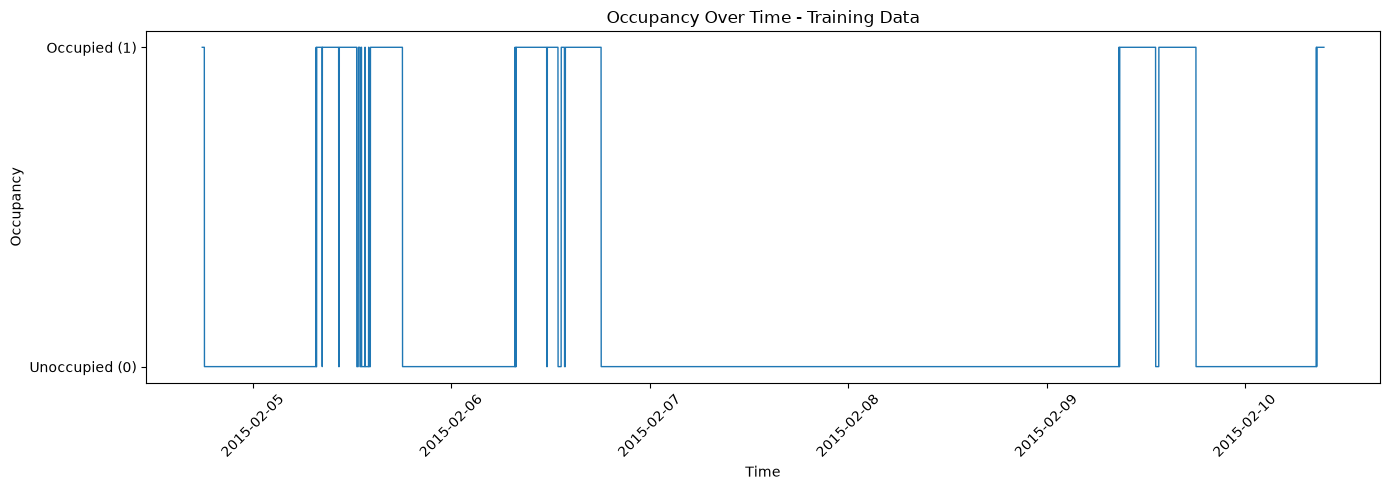

In [10]:
# ============================================================
# Cell 10 - Occupancy Over Time
# ============================================================

plt.figure(
    figsize=(14, 5)
)

plt.plot(
    train["date"],
    train["Occupancy"],
    linewidth=1
)

plt.xlabel("Time")
plt.ylabel("Occupancy")

plt.title(
    "Occupancy Over Time - Training Data"
)

plt.yticks(
    [0, 1],
    ["Unoccupied (0)", "Occupied (1)"]
)

plt.xticks(
    rotation=45
)

plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "00_occupancy_over_time.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

In [11]:
# ============================================================
# Cell 11 - Standardization
# ============================================================

scaler = StandardScaler()

# IMPORTANT:
# Fit scaler ONLY on training data
scaler.fit(
    train[FEATURES]
)

# Transform all datasets
train_scaled = scaler.transform(
    train[FEATURES]
).astype(np.float32)

validation_scaled = scaler.transform(
    validation[FEATURES]
).astype(np.float32)

test_scaled = scaler.transform(
    test[FEATURES]
).astype(np.float32)

print(
    "Standardization completed."
)

print(
    "\nTraining means after scaling:"
)

print(
    train_scaled.mean(axis=0)
)

print(
    "\nTraining standard deviations after scaling:"
)

print(
    train_scaled.std(axis=0)
)

Standardization completed.

Training means after scaling:
[2.9981656e-08 0.0000000e+00 2.2486242e-08 2.0612388e-08 0.0000000e+00]

Training standard deviations after scaling:
[1. 1. 1. 1. 1.]


In [12]:
# ============================================================
# Cell 12 - Sliding Window Function
# ============================================================

def create_sequences(
    df,
    feature_array,
    window_size=10,
    horizon=1,
    max_gap_seconds=90
):
    """
    Create time-series samples.

    Example:

    window_size = 10
    horizon = 1

    Input:
        t-9, t-8, ..., t

    Target:
        t+1
    """

    feature_array = np.asarray(
        feature_array,
        dtype=np.float32
    )

    y = df[TARGET].to_numpy(
        dtype=np.int32
    )

    timestamps = df["date"].to_numpy()

    # Time differences in seconds
    gap_seconds = (
        df["date"]
        .diff()
        .dt.total_seconds()
        .to_numpy()
    )

    X_sequences = []
    y_sequences = []
    target_times = []

    # --------------------------------------------------------
    # Start at first point where 10 history points + target
    # are available
    # --------------------------------------------------------

    first_target_index = (
        window_size + horizon - 1
    )

    for target_index in range(
        first_target_index,
        len(df)
    ):

        input_end = (
            target_index - horizon
        )

        input_start = (
            input_end -
            window_size +
            1
        )

        # ----------------------------------------------------
        # Make sure there are no large time gaps
        # inside the sequence
        # ----------------------------------------------------

        relevant_gaps = gap_seconds[
            input_start + 1:
            target_index + 1
        ]

        if (
            len(relevant_gaps) > 0
            and np.any(
                relevant_gaps >
                max_gap_seconds
            )
        ):
            continue

        # ----------------------------------------------------
        # Input: previous 10 minutes
        # ----------------------------------------------------

        X_sequences.append(
            feature_array[
                input_start:
                input_end + 1
            ]
        )

        # ----------------------------------------------------
        # Target: next minute
        # ----------------------------------------------------

        y_sequences.append(
            y[target_index]
        )

        target_times.append(
            timestamps[target_index]
        )

    X_sequences = np.asarray(
        X_sequences,
        dtype=np.float32
    )

    y_sequences = np.asarray(
        y_sequences,
        dtype=np.int32
    )

    target_times = pd.to_datetime(
        target_times
    )

    return (
        X_sequences,
        y_sequences,
        target_times
    )

In [13]:
# ============================================================
# Cell 13 - Create Sequences for LSTM / CNN
# ============================================================

X_train, y_train, train_target_times = create_sequences(
    train,
    train_scaled,
    WINDOW_SIZE,
    HORIZON,
    MAX_GAP_SECONDS
)

X_val, y_val, val_target_times = create_sequences(
    validation,
    validation_scaled,
    WINDOW_SIZE,
    HORIZON,
    MAX_GAP_SECONDS
)

X_test, y_test, test_target_times = create_sequences(
    test,
    test_scaled,
    WINDOW_SIZE,
    HORIZON,
    MAX_GAP_SECONDS
)

print("Training:")
print("X:", X_train.shape)
print("y:", y_train.shape)

print("\nValidation:")
print("X:", X_val.shape)
print("y:", y_val.shape)

print("\nTest:")
print("X:", X_test.shape)
print("y:", y_test.shape)

Training:
X: (8133, 10, 5)
y: (8133,)

Validation:
X: (2655, 10, 5)
y: (2655,)

Test:
X: (9742, 10, 5)
y: (9742,)


In [14]:
# ============================================================
# Cell 14 - Inspect One Sliding Window
# ============================================================

sample_index = 0

print(
    "One sample shape:"
)

print(
    X_train[sample_index].shape
)

print(
    "\nOne sample:"
)

print(
    X_train[sample_index]
)

print(
    "\nTarget:"
)

print(
    y_train[sample_index]
)

print(
    "\nTarget time:"
)

print(
    train_target_times[sample_index]
)

One sample shape:
(10, 5)

One sample:
[[2.51847    0.27852622 1.5737628  0.3649481  1.0917569 ]
 [2.4889674  0.2777126  1.5917351  0.34188107 1.080555  ]
 [2.4889674  0.27364454 1.5737628  0.34029025 1.0758882 ]
 [2.4889674  0.26550838 1.5737628  0.32358652 1.0665547 ]
 [2.439796   0.26550838 1.5737628  0.3116553  1.0495229 ]
 [2.439796   0.26550838 1.5378182  0.30051953 1.0495229 ]
 [2.439796   0.26550838 1.5378182  0.30264062 1.0495229 ]
 [2.439796   0.26550838 1.5378182  0.2941562  1.0495229 ]
 [2.439796   0.26550838 1.5378182  0.26340017 1.0495229 ]
 [2.4152105  0.2609883  1.5378182  0.25915796 1.0358628 ]]

Target:
1

Target time:
2015-02-04 18:01:00


In [15]:
# ============================================================
# Cell 15 - Class Weights
# ============================================================

classes = np.unique(
    y_train
)

class_weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y_train
)

class_weight_dict = {
    int(cls): float(weight)
    for cls, weight
    in zip(classes, class_weights)
}

print(
    "Class weights:"
)

print(
    class_weight_dict
)

Class weights:
{0: 0.6340037418147801, 1: 2.3656195462478187}


In [16]:
# ============================================================
# Cell 16 - Build LSTM Model
# ============================================================

lstm_model = Sequential([
    
    Input(
        shape=(
            WINDOW_SIZE,
            len(FEATURES)
        )
    ),

    LSTM(
        32
    ),

    Dropout(
        0.20
    ),

    Dense(
        16,
        activation="relu"
    ),

    Dense(
        1,
        activation="sigmoid"
    )
])

lstm_model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

lstm_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 32)             │         4,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,409 (21.13 KB)

 Trainable params: 5,409 (21.13 KB)

 Non-trainable params: 0 (0.00 B)

In [17]:
# ============================================================
# Cell 17 - Train LSTM
# ============================================================

early_stopping_lstm = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

history_lstm = lstm_model.fit(

    X_train,
    y_train,

    validation_data=(
        X_val,
        y_val
    ),

    epochs=EPOCHS,

    batch_size=BATCH_SIZE,

    class_weight=class_weight_dict,

    callbacks=[
        early_stopping_lstm
    ],

    shuffle=False,

    verbose=1
)

Epoch 1/30
255/255 ━━━━━━━━━━━━━━━━━━━━ 6s 11ms/step - accuracy: 0.8635 - loss: 0.3311 - val_accuracy: 0.9213 - val_loss: 0.1750
Epoch 2/30
255/255 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - accuracy: 0.9396 - loss: 0.1230 - val_accuracy: 0.9684 - val_loss: 0.1301
Epoch 3/30
255/255 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - accuracy: 0.9766 - loss: 0.0910 - val_accuracy: 0.9669 - val_loss: 0.1478
Epoch 4/30
255/255 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - accuracy: 0.9787 - loss: 0.0817 - val_accuracy: 0.9710 - val_loss: 0.1125
Epoch 5/30
255/255 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - accuracy: 0.9796 - loss: 0.0779 - val_accuracy: 0.9714 - val_loss: 0.1091
Epoch 6/30
255/255 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.9816 - loss: 0.0724 - val_accuracy: 0.9718 - val_loss: 0.1082
Epoch 7/30
255/255 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - accuracy: 0.9828 - loss: 0.0680 - val_accuracy: 0.9710 - val_loss: 0.1099
Epoch 8/30
255/255 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - accuracy: 0.9839 - loss: 0.0652 - val_accuracy: 0

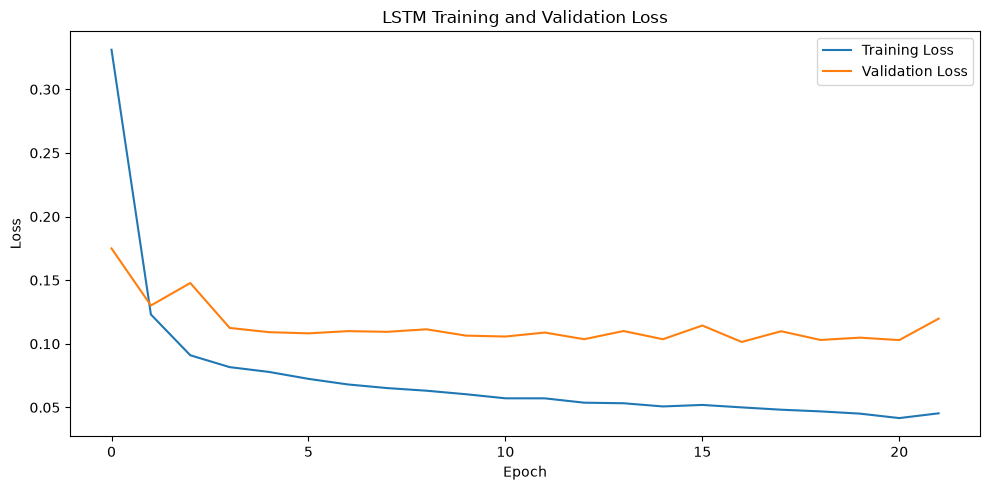

In [18]:
# ============================================================
# Cell 18 - LSTM Training Curve
# ============================================================

plt.figure(
    figsize=(10, 5)
)

plt.plot(
    history_lstm.history["loss"],
    label="Training Loss"
)

plt.plot(
    history_lstm.history["val_loss"],
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")

plt.title(
    "LSTM Training and Validation Loss"
)

plt.legend()

plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "01_lstm_loss.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

In [19]:
# ============================================================
# Cell 19 - Build 1D-CNN Model
# ============================================================

cnn_model = Sequential([

    Input(
        shape=(
            WINDOW_SIZE,
            len(FEATURES)
        )
    ),

    Conv1D(
        filters=32,
        kernel_size=3,
        activation="relu"
    ),

    Conv1D(
        filters=16,
        kernel_size=3,
        activation="relu"
    ),

    GlobalAveragePooling1D(),

    Dense(
        16,
        activation="relu"
    ),

    Dropout(
        0.20
    ),

    Dense(
        1,
        activation="sigmoid"
    )
])

cnn_model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

cnn_model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d (Conv1D)                 │ (None, 8, 32)          │           512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_1 (Conv1D)               │ (None, 6, 16)          │         1,552 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling1d        │ (None, 16)             │             0 │
│ (GlobalAveragePooling1D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 16)             │           272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,353 (9.19 KB)

 Trainable params: 2,353 (9.19 KB)

 Non-trainable params: 0 (0.00 B)

In [20]:
# ============================================================
# Cell 20 - Train 1D-CNN
# ============================================================

early_stopping_cnn = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

history_cnn = cnn_model.fit(

    X_train,
    y_train,

    validation_data=(
        X_val,
        y_val
    ),

    epochs=EPOCHS,

    batch_size=BATCH_SIZE,

    class_weight=class_weight_dict,

    callbacks=[
        early_stopping_cnn
    ],

    shuffle=False,

    verbose=1
)

Epoch 1/30
255/255 ━━━━━━━━━━━━━━━━━━━━ 5s 9ms/step - accuracy: 0.9045 - loss: 0.3238 - val_accuracy: 0.9556 - val_loss: 0.1502
Epoch 2/30
255/255 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - accuracy: 0.9673 - loss: 0.1135 - val_accuracy: 0.9706 - val_loss: 0.1178
Epoch 3/30
255/255 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - accuracy: 0.9745 - loss: 0.0963 - val_accuracy: 0.9706 - val_loss: 0.1295
Epoch 4/30
255/255 ━━━━━━━━━━━━━━━━━━━━ 3s 10ms/step - accuracy: 0.9766 - loss: 0.0967 - val_accuracy: 0.9714 - val_loss: 0.1228
Epoch 5/30
255/255 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - accuracy: 0.9781 - loss: 0.0927 - val_accuracy: 0.9721 - val_loss: 0.1177
Epoch 6/30
255/255 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - accuracy: 0.9784 - loss: 0.0867 - val_accuracy: 0.9718 - val_loss: 0.1159
Epoch 7/30
255/255 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.9806 - loss: 0.0882 - val_accuracy: 0.9725 - val_loss: 0.1140
Epoch 8/30
255/255 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - accuracy: 0.9825 - loss: 0.0835 - val_accuracy: 0

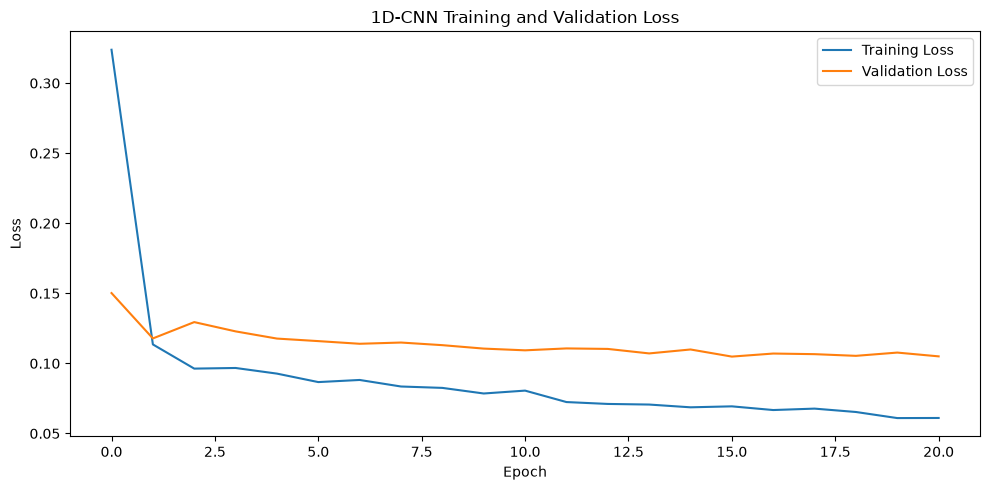

In [21]:
# ============================================================
# Cell 21 - CNN Training Curve
# ============================================================

plt.figure(
    figsize=(10, 5)
)

plt.plot(
    history_cnn.history["loss"],
    label="Training Loss"
)

plt.plot(
    history_cnn.history["val_loss"],
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")

plt.title(
    "1D-CNN Training and Validation Loss"
)

plt.legend()

plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "02_cnn_loss.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

In [22]:
# ============================================================
# Cell 22 - Prepare XGBoost Input
# ============================================================

# XGBoost does not require standardized values.
# We therefore create windows from RAW features.

X_train_raw, _, _ = create_sequences(
    train,
    train[FEATURES].to_numpy(dtype=np.float32),
    WINDOW_SIZE,
    HORIZON,
    MAX_GAP_SECONDS
)

X_val_raw, _, _ = create_sequences(
    validation,
    validation[FEATURES].to_numpy(dtype=np.float32),
    WINDOW_SIZE,
    HORIZON,
    MAX_GAP_SECONDS
)

X_test_raw, _, _ = create_sequences(
    test,
    test[FEATURES].to_numpy(dtype=np.float32),
    WINDOW_SIZE,
    HORIZON,
    MAX_GAP_SECONDS
)

# Flatten:
# (samples, 10, 5)
#          ↓
# (samples, 50)

X_train_xgb = X_train_raw.reshape(
    X_train_raw.shape[0],
    -1
)

X_val_xgb = X_val_raw.reshape(
    X_val_raw.shape[0],
    -1
)

X_test_xgb = X_test_raw.reshape(
    X_test_raw.shape[0],
    -1
)

print(
    "X_train_xgb:",
    X_train_xgb.shape
)

print(
    "X_val_xgb:",
    X_val_xgb.shape
)

print(
    "X_test_xgb:",
    X_test_xgb.shape
)

X_train_xgb: (8133, 50)
X_val_xgb: (2655, 50)
X_test_xgb: (9742, 50)


In [23]:
# ============================================================
# Cell 23 - Train XGBoost
# ============================================================

negative_count = int(
    np.sum(y_train == 0)
)

positive_count = int(
    np.sum(y_train == 1)
)

scale_pos_weight = (
    negative_count /
    positive_count
)

print(
    "Negative samples:",
    negative_count
)

print(
    "Positive samples:",
    positive_count
)

print(
    "scale_pos_weight:",
    scale_pos_weight
)


xgb_model = XGBClassifier(

    n_estimators=300,

    max_depth=5,

    learning_rate=0.05,

    subsample=0.8,

    colsample_bytree=0.8,

    objective="binary:logistic",

    eval_metric="logloss",

    scale_pos_weight=scale_pos_weight,

    random_state=SEED,

    n_jobs=-1,

    tree_method="hist"
)


xgb_model.fit(

    X_train_xgb,
    y_train,

    eval_set=[
        (
            X_val_xgb,
            y_val
        )
    ],

    verbose=False
)

print(
    "\nXGBoost training completed."
)

Negative samples: 6414
Positive samples: 1719
scale_pos_weight: 3.731239092495637

XGBoost training completed.


In [24]:
# ============================================================
# Cell 24 - Generate Predictions
# ============================================================

print("Generating LSTM predictions...")

lstm_val_prob = (
    lstm_model
    .predict(
        X_val,
        batch_size=BATCH_SIZE,
        verbose=0
    )
    .ravel()
)

lstm_test_prob = (
    lstm_model
    .predict(
        X_test,
        batch_size=BATCH_SIZE,
        verbose=0
    )
    .ravel()
)


print("Generating CNN predictions...")

cnn_val_prob = (
    cnn_model
    .predict(
        X_val,
        batch_size=BATCH_SIZE,
        verbose=0
    )
    .ravel()
)

cnn_test_prob = (
    cnn_model
    .predict(
        X_test,
        batch_size=BATCH_SIZE,
        verbose=0
    )
    .ravel()
)


print("Generating XGBoost predictions...")

xgb_val_prob = (
    xgb_model
    .predict_proba(
        X_val_xgb
    )[:, 1]
)

xgb_test_prob = (
    xgb_model
    .predict_proba(
        X_test_xgb
    )[:, 1]
)

print("\nAll predictions generated.")

Generating LSTM predictions...
Generating CNN predictions...
Generating XGBoost predictions...

All predictions generated.


In [25]:
# ============================================================
# Cell 25 - Optimize Classification Threshold
# ============================================================

def find_best_threshold(
    y_true,
    probabilities
):

    thresholds = np.arange(
        0.10,
        0.91,
        0.01
    )

    best_threshold = 0.50
    best_f1 = -1.0

    for threshold in thresholds:

        predictions = (
            probabilities >= threshold
        ).astype(int)

        current_f1 = f1_score(
            y_true,
            predictions,
            zero_division=0
        )

        if current_f1 > best_f1:

            best_f1 = current_f1

            best_threshold = float(
                threshold
            )

    return (
        best_threshold,
        best_f1
    )

In [26]:
# ============================================================
# Cell 26 - Evaluation Function
# ============================================================

def evaluate_model(
    model_name,
    y_true,
    probabilities,
    threshold
):

    predictions = (
        probabilities >= threshold
    ).astype(int)

    metrics = {

        "Model": model_name,

        "Threshold": threshold,

        "Accuracy":
            accuracy_score(
                y_true,
                predictions
            ),

        "Precision":
            precision_score(
                y_true,
                predictions,
                zero_division=0
            ),

        "Recall":
            recall_score(
                y_true,
                predictions,
                zero_division=0
            ),

        "F1":
            f1_score(
                y_true,
                predictions,
                zero_division=0
            ),

        "ROC-AUC":
            roc_auc_score(
                y_true,
                probabilities
            )
    }

    return (
        metrics,
        predictions
    )

In [27]:
# ============================================================
# Cell 27 - Evaluate LSTM / CNN / XGBoost
# ============================================================

model_probabilities = {

    "LSTM": {
        "validation": lstm_val_prob,
        "test": lstm_test_prob
    },

    "1D-CNN": {
        "validation": cnn_val_prob,
        "test": cnn_test_prob
    },

    "XGBoost": {
        "validation": xgb_val_prob,
        "test": xgb_test_prob
    }
}


all_metrics = []

test_predictions = {}


for model_name, probs in model_probabilities.items():

    # --------------------------------------------------------
    # Find threshold ONLY on validation set
    # --------------------------------------------------------

    best_threshold, validation_f1 = (
        find_best_threshold(
            y_val,
            probs["validation"]
        )
    )

    # --------------------------------------------------------
    # Apply threshold to test set
    # --------------------------------------------------------

    metrics, predictions = (
        evaluate_model(
            model_name,
            y_test,
            probs["test"],
            best_threshold
        )
    )

    # Add validation F1
    metrics["Validation F1"] = (
        validation_f1
    )

    all_metrics.append(
        metrics
    )

    test_predictions[
        model_name
    ] = {

        "probability":
            probs["test"],

        "prediction":
            predictions,

        "threshold":
            best_threshold
    }


metrics_df = pd.DataFrame(
    all_metrics
)

metrics_df = metrics_df.sort_values(
    "F1",
    ascending=False
).reset_index(drop=True)


print(
    metrics_df.to_string(
        index=False
    )
)

  Model  Threshold  Accuracy  Precision   Recall       F1  ROC-AUC  Validation F1
   LSTM       0.88  0.992712   0.976283 0.989210 0.982704 0.995994       0.968496
XGBoost       0.11  0.987169   0.947196 0.994115 0.970089 0.996103       0.968957
 1D-CNN       0.70  0.985527   0.951905 0.980383 0.965934 0.993240       0.968464


In [28]:
# ============================================================
# Cell 28 - Performance Table
# ============================================================

performance_table = metrics_df.copy()

numeric_columns = [
    "Threshold",
    "Accuracy",
    "Precision",
    "Recall",
    "F1",
    "ROC-AUC",
    "Validation F1"
]

for column in numeric_columns:

    performance_table[column] = (
        performance_table[column]
        .round(4)
    )

display(
    performance_table
)

,Model,Threshold,Accuracy,Precision,Recall,F1,ROC-AUC,Validation F1
0,LSTM,0.88,0.9927,0.9763,0.9892,0.9827,0.9960,0.9685
1,XGBoost,0.11,0.9872,0.9472,0.9941,0.9701,0.9961,0.9690
2,1D-CNN,0.70,0.9855,0.9519,0.9804,0.9659,0.9932,0.9685


In [29]:
# ============================================================
# Cell 29 - Detailed Classification Reports
# ============================================================

for model_name in [
    "LSTM",
    "1D-CNN",
    "XGBoost"
]:

    print("\n")
    print("=" * 70)
    print(model_name)
    print("=" * 70)

    print(
        classification_report(
            y_test,
            test_predictions[
                model_name
            ]["prediction"],
            target_names=[
                "Unoccupied (0)",
                "Occupied (1)"
            ],
            digits=4
        )
    )



LSTM
                precision    recall  f1-score   support

Unoccupied (0)     0.9971    0.9936    0.9954      7703
  Occupied (1)     0.9763    0.9892    0.9827      2039

      accuracy                         0.9927      9742
     macro avg     0.9867    0.9914    0.9890      9742
  weighted avg     0.9928    0.9927    0.9927      9742



1D-CNN
                precision    recall  f1-score   support

Unoccupied (0)     0.9948    0.9869    0.9908      7703
  Occupied (1)     0.9519    0.9804    0.9659      2039

      accuracy                         0.9855      9742
     macro avg     0.9733    0.9836    0.9784      9742
  weighted avg     0.9858    0.9855    0.9856      9742



XGBoost
                precision    recall  f1-score   support

Unoccupied (0)     0.9984    0.9853    0.9918      7703
  Occupied (1)     0.9472    0.9941    0.9701      2039

      accuracy                         0.9872      9742
     macro avg     0.9728    0.9897    0.9810      9742
  weighted avg


LSTM
[[7654   49]
 [  22 2017]]


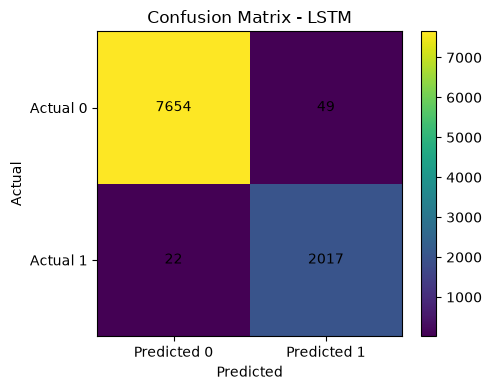


1D-CNN
[[7602  101]
 [  40 1999]]


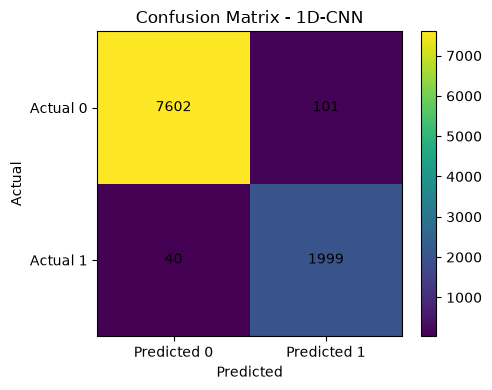


XGBoost
[[7590  113]
 [  12 2027]]


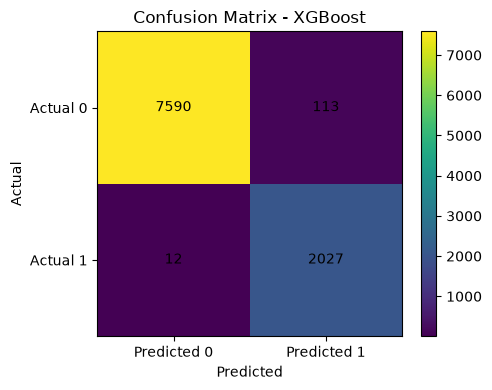

In [30]:
# ============================================================
# Cell 30 - Confusion Matrices
# ============================================================

for model_name in [
    "LSTM",
    "1D-CNN",
    "XGBoost"
]:

    predictions = (
        test_predictions[
            model_name
        ]["prediction"]
    )

    cm = confusion_matrix(
        y_test,
        predictions
    )

    print(
        f"\n{model_name}"
    )

    print(cm)

    plt.figure(
        figsize=(5, 4)
    )

    plt.imshow(
        cm,
        interpolation="nearest"
    )

    plt.title(
        f"Confusion Matrix - {model_name}"
    )

    plt.colorbar()

    plt.xticks(
        [0, 1],
        ["Predicted 0", "Predicted 1"]
    )

    plt.yticks(
        [0, 1],
        ["Actual 0", "Actual 1"]
    )

    for row in range(2):

        for col in range(2):

            plt.text(
                col,
                row,
                cm[row, col],
                ha="center",
                va="center"
            )

    plt.xlabel(
        "Predicted"
    )

    plt.ylabel(
        "Actual"
    )

    plt.tight_layout()

    filename = (
        "confusion_matrix_"
        + model_name
          .lower()
          .replace("-", "_")
        + ".png"
    )

    plt.savefig(
        OUTPUT_DIR / filename,
        dpi=200,
        bbox_inches="tight"
    )

    plt.show()

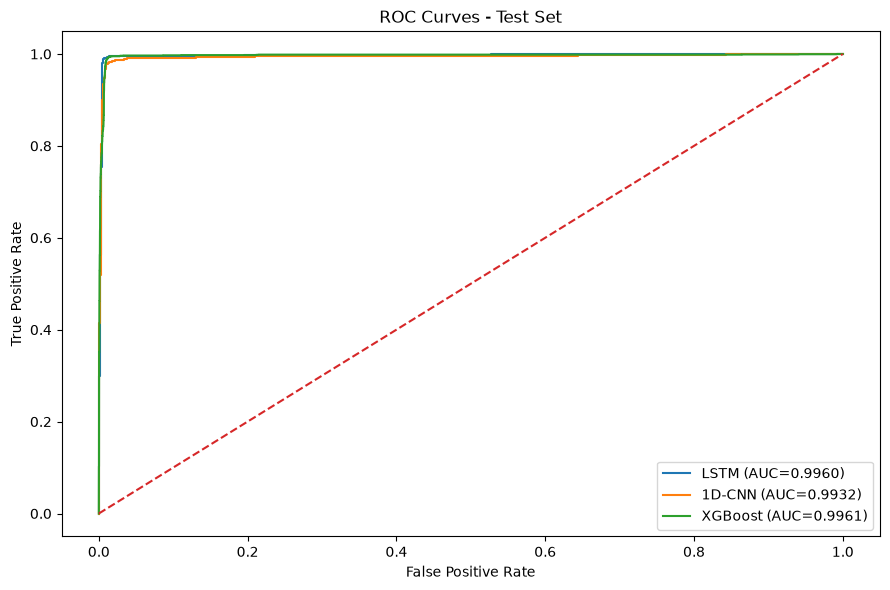

In [31]:
# ============================================================
# Cell 31 - ROC Curves
# ============================================================

plt.figure(
    figsize=(9, 6)
)

for model_name in [
    "LSTM",
    "1D-CNN",
    "XGBoost"
]:

    probabilities = (
        test_predictions[
            model_name
        ]["probability"]
    )

    fpr, tpr, _ = roc_curve(
        y_test,
        probabilities
    )

    auc = roc_auc_score(
        y_test,
        probabilities
    )

    plt.plot(
        fpr,
        tpr,
        label=f"{model_name} (AUC={auc:.4f})"
    )


plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--"
)

plt.xlabel(
    "False Positive Rate"
)

plt.ylabel(
    "True Positive Rate"
)

plt.title(
    "ROC Curves - Test Set"
)

plt.legend()

plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "03_roc_curves.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

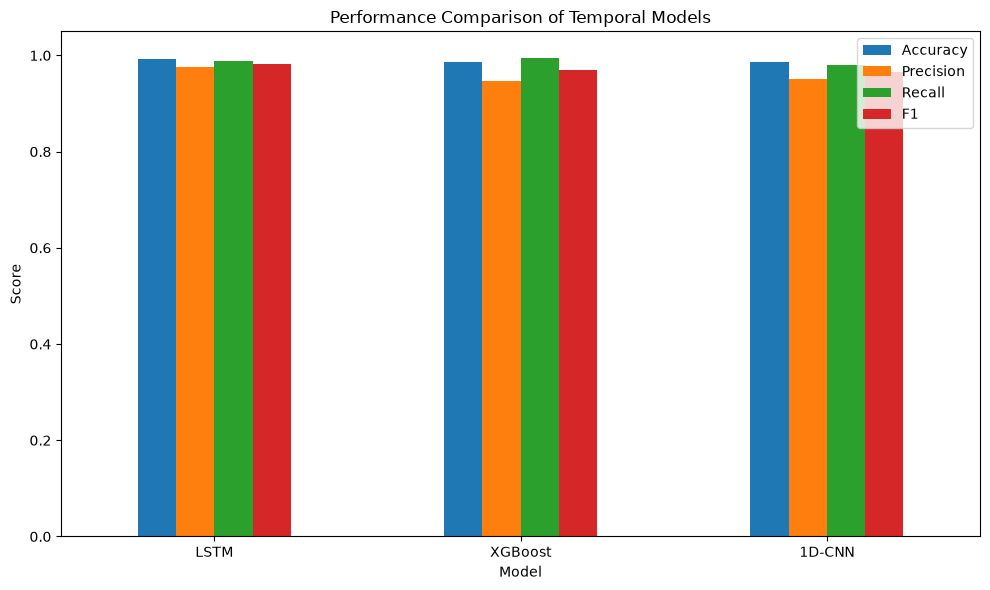

In [32]:
# ============================================================
# Cell 32 - Model Performance Comparison
# ============================================================

comparison_df = (
    metrics_df
    .set_index("Model")
    [
        [
            "Accuracy",
            "Precision",
            "Recall",
            "F1"
        ]
    ]
)

plt.figure(
    figsize=(10, 6)
)

comparison_df.plot(
    kind="bar",
    ax=plt.gca()
)

plt.ylim(
    0,
    1.05
)

plt.ylabel(
    "Score"
)

plt.title(
    "Performance Comparison of Temporal Models"
)

plt.xticks(
    rotation=0
)

plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "04_model_comparison.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

In [33]:
# ============================================================
# Cell 33 - Identify Best Model
# ============================================================

best_row = (
    metrics_df
    .sort_values(
        "F1",
        ascending=False
    )
    .iloc[0]
)

BEST_MODEL = best_row["Model"]

print(
    "Best model based on test F1:"
)

print(
    BEST_MODEL
)

print(
    "\nF1:",
    round(
        best_row["F1"],
        4
    )
)

print(
    "Accuracy:",
    round(
        best_row["Accuracy"],
        4
    )
)

print(
    "Recall:",
    round(
        best_row["Recall"],
        4
    )
)

print(
    "ROC-AUC:",
    round(
        best_row["ROC-AUC"],
        4
    )
)

Best model based on test F1:
LSTM

F1: 0.9827
Accuracy: 0.9927
Recall: 0.9892
ROC-AUC: 0.996


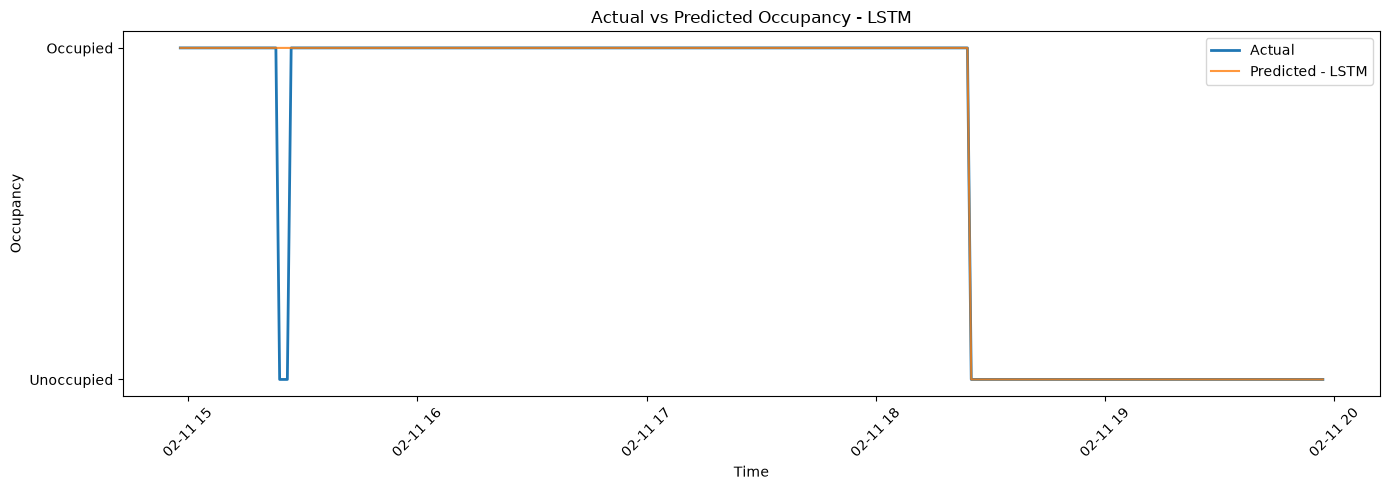

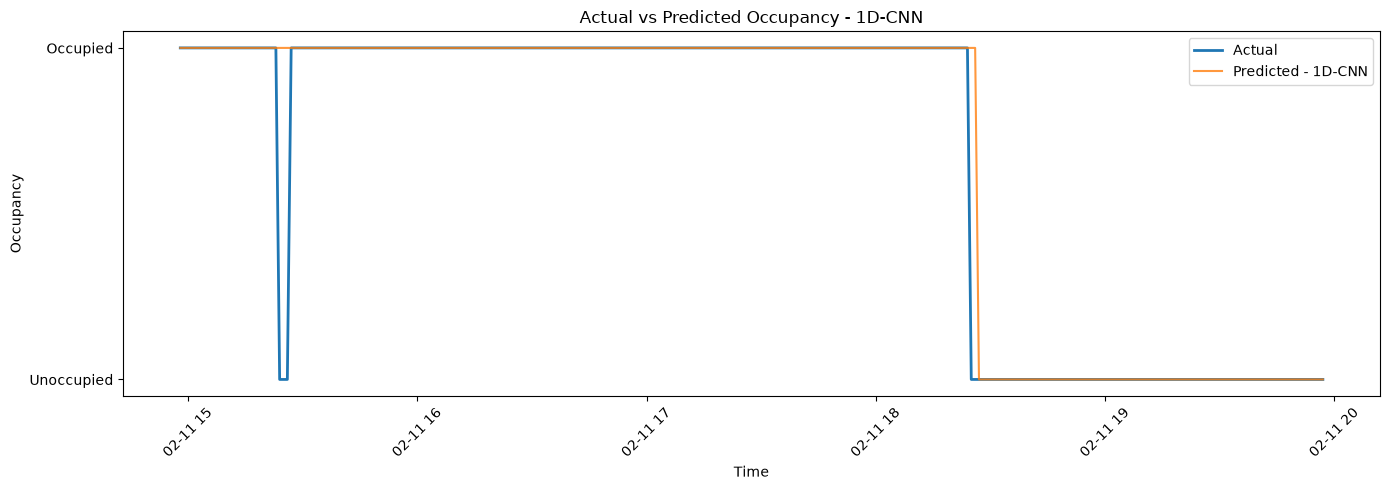

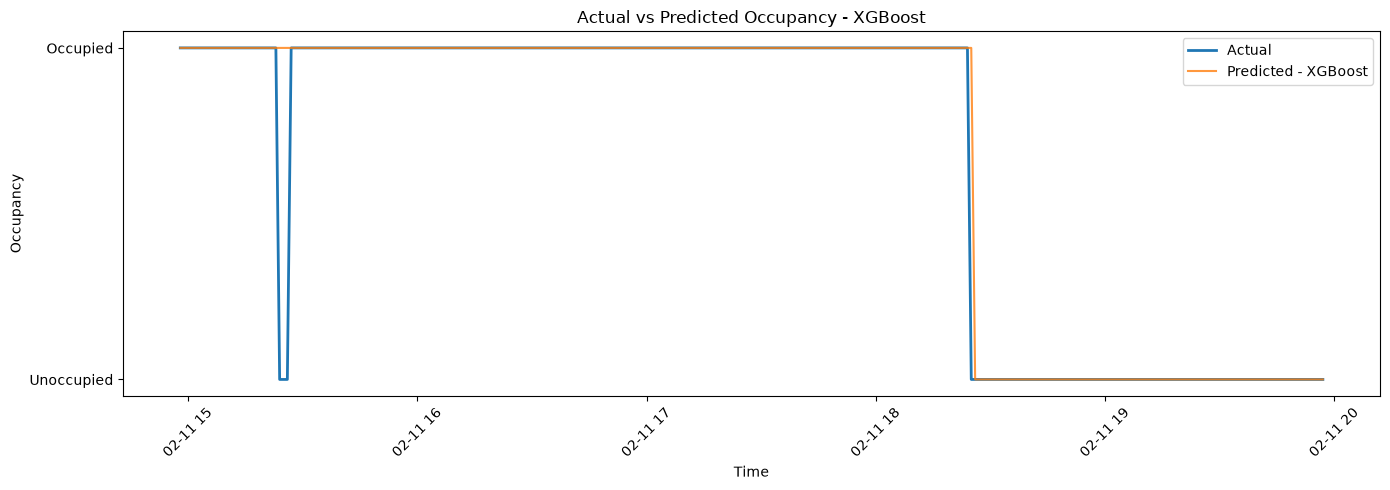

In [42]:
# ============================================================
# Cell 34 - Actual vs Predicted Occupancy
# All Three Models
# ============================================================

PLOT_POINTS = min(
    300,
    len(y_test)
)

MODEL_NAMES = [
    "LSTM",
    "1D-CNN",
    "XGBoost"
]

for model_name in MODEL_NAMES:

    # --------------------------------------------------------
    # Get predictions for current model
    # --------------------------------------------------------

    model_predictions = (
        test_predictions[
            model_name
        ]["prediction"]
    )

    # --------------------------------------------------------
    # Select first PLOT_POINTS
    # --------------------------------------------------------

    plot_times = (
        test_target_times[
            :PLOT_POINTS
        ]
    )

    plot_actual = (
        y_test[
            :PLOT_POINTS
        ]
    )

    plot_predicted = (
        model_predictions[
            :PLOT_POINTS
        ]
    )

    # --------------------------------------------------------
    # Plot
    # --------------------------------------------------------

    plt.figure(
        figsize=(14, 5)
    )

    plt.plot(
        plot_times,
        plot_actual,
        label="Actual",
        linewidth=2
    )

    plt.plot(
        plot_times,
        plot_predicted,
        label=f"Predicted - {model_name}",
        alpha=0.8
    )

    plt.xlabel(
        "Time"
    )

    plt.ylabel(
        "Occupancy"
    )

    plt.yticks(
        [0, 1],
        ["Unoccupied", "Occupied"]
    )

    plt.title(
        f"Actual vs Predicted Occupancy - {model_name}"
    )

    plt.xticks(
        rotation=45
    )

    plt.legend()

    plt.tight_layout()

    # --------------------------------------------------------
    # Save each model's figure
    # --------------------------------------------------------

    filename = (
        "06_actual_vs_predicted_"
        + model_name
          .lower()
          .replace("-", "_")
        + ".png"
    )

    plt.savefig(
        OUTPUT_DIR / filename,
        dpi=200,
        bbox_inches="tight"
    )

    plt.show()

In [37]:
# ============================================================
# Cell 35 - Save Test Predictions
# ============================================================

predictions_df = pd.DataFrame({

    "date":
        test_target_times,

    "Actual_Occupancy":
        y_test,

    "LSTM_Probability":
        test_predictions[
            "LSTM"
        ]["probability"],

    "LSTM_Prediction":
        test_predictions[
            "LSTM"
        ]["prediction"],

    "CNN_Probability":
        test_predictions[
            "1D-CNN"
        ]["probability"],

    "CNN_Prediction":
        test_predictions[
            "1D-CNN"
        ]["prediction"],

    "XGBoost_Probability":
        test_predictions[
            "XGBoost"
        ]["probability"],

    "XGBoost_Prediction":
        test_predictions[
            "XGBoost"
        ]["prediction"]
})

display(
    predictions_df.head(20)
)

predictions_df.to_csv(
    OUTPUT_DIR / "test_predictions.csv",
    index=False
)

print(
    "\nPrediction file saved."
)

,date,Actual_Occupancy,LSTM_Probability,LSTM_Prediction,CNN_Probability,CNN_Prediction,XGBoost_Probability,XGBoost_Prediction
0,2015-02-11 14:57:59,1,0.987229,1,0.983762,1,0.999883,1
1,2015-02-11 14:58:59,1,0.987478,1,0.983933,1,0.999888,1
2,2015-02-11 15:00:00,1,0.987839,1,0.984195,1,0.999897,1
3,2015-02-11 15:01:00,1,0.988269,1,0.984660,1,0.999911,1
4,2015-02-11 15:02:00,1,0.988366,1,0.985068,1,0.999934,1
5,2015-02-11 15:03:00,1,0.988493,1,0.985546,1,0.999926,1
6,2015-02-11 15:04:00,1,0.988328,1,0.985802,1,0.999905,1
7,2015-02-11 15:04:59,1,0.988699,1,0.986090,1,0.999899,1
8,2015-02-11 15:06:00,1,0.988625,1,0.986240,1,0.999933,1
9,2015-02-11 15:07:00,1,0.989063,1,0.986336,1,0.999936,1



Prediction file saved.


In [38]:
# ============================================================
# Cell 36 - Save Metrics
# ============================================================

metrics_df.to_csv(
    OUTPUT_DIR / "model_metrics.csv",
    index=False
)

print(
    "Metrics saved to:"
)

print(
    OUTPUT_DIR / "model_metrics.csv"
)

Metrics saved to:
C:\Users\admin\smart_city\experiment_B_results\model_metrics.csv


In [39]:
# ============================================================
# Cell 37 - Save Trained Models
# ============================================================

# LSTM
lstm_model.save(
    OUTPUT_DIR / "lstm_model.keras"
)

# CNN
cnn_model.save(
    OUTPUT_DIR / "cnn_model.keras"
)

# XGBoost
xgb_model.save_model(
    OUTPUT_DIR / "xgboost_model.json"
)

# Scaler
joblib.dump(
    scaler,
    OUTPUT_DIR / "standard_scaler.joblib"
)

print(
    "All trained models and scaler saved."
)

All trained models and scaler saved.


In [40]:
# ============================================================
# Cell 38 - Save Experiment Configuration
# ============================================================

config = {

    "features":
        FEATURES,

    "target":
        TARGET,

    "window_size":
        WINDOW_SIZE,

    "horizon":
        HORIZON,

    "max_gap_seconds":
        MAX_GAP_SECONDS,

    "epochs":
        EPOCHS,

    "batch_size":
        BATCH_SIZE,

    "best_model":
        BEST_MODEL
}

config_df = pd.DataFrame(
    [config]
)

config_df.to_json(
    OUTPUT_DIR / "experiment_config.json",
    orient="records",
    indent=4
)

print(
    config_df.T
)

                                                                 0
features         [Temperature, Humidity, Light, CO2, HumidityRa...
target                                                   Occupancy
window_size                                                     10
horizon                                                          1
max_gap_seconds                                                 90
epochs                                                          30
batch_size                                                      32
best_model                                                    LSTM


In [41]:
# ============================================================
# Cell 39 - Final Experiment Summary
# ============================================================

print("\n")
print("=" * 80)
print("EXPERIMENT B COMPLETED")
print("=" * 80)

print("\nResearch Question:")
print(
    "Can historical sensor patterns improve "
    "next-minute occupancy prediction?"
)

print("\nInput:")
print(
    "Previous 10 minutes × 5 sensor features"
)

print("\nTarget:")
print(
    "Occupancy at the next minute (0/1)"
)

print("\nModels:")
print(
    "1. LSTM"
)

print(
    "2. 1D-CNN"
)

print(
    "3. XGBoost"
)

print("\nResults:")
display(
    metrics_df
)

print(
    "\nBest model:",
    BEST_MODEL
)

print(
    "\nOutput directory:"
)

print(
    OUTPUT_DIR.resolve()
)

print("\nGenerated files:")

for file in sorted(
    OUTPUT_DIR.iterdir()
):

    print(
        " -",
        file.name
    )

print(
    "\nExperiment B finished successfully."
)



EXPERIMENT B COMPLETED

Research Question:
Can historical sensor patterns improve next-minute occupancy prediction?

Input:
Previous 10 minutes × 5 sensor features

Target:
Occupancy at the next minute (0/1)

Models:
1. LSTM
2. 1D-CNN
3. XGBoost

Results:


,Model,Threshold,Accuracy,Precision,Recall,F1,ROC-AUC,Validation F1
0,LSTM,0.88,0.992712,0.976283,0.989210,0.982704,0.995994,0.968496
1,XGBoost,0.11,0.987169,0.947196,0.994115,0.970089,0.996103,0.968957
2,1D-CNN,0.70,0.985527,0.951905,0.980383,0.965934,0.993240,0.968464



Best model: LSTM

Output directory:
C:\Users\admin\smart_city\experiment_B_results

Generated files:
 - 00_occupancy_over_time.png
 - 01_lstm_loss.png
 - 02_cnn_loss.png
 - 03_roc_curves.png
 - 04_model_comparison.png
 - 06_actual_vs_predicted.png
 - cnn_model.keras
 - confusion_matrix_1d_cnn.png
 - confusion_matrix_lstm.png
 - confusion_matrix_xgboost.png
 - experiment_config.json
 - lstm_model.keras
 - model_metrics.csv
 - standard_scaler.joblib
 - test_predictions.csv
 - xgboost_model.json

Experiment B finished successfully.
